In [1]:
import sys

sys.path.append("../src")

In [2]:
from data.loader import load_market_data
from analytics.returns import calculate_simple_returns
from analytics.risk import (
    annualized_volatility,
    sharpe_ratio,
    maximum_drawdown
)

In [3]:
data = load_market_data(
    "AAPL",
    "2018-01-01",
    "2025-01-01"
)

[*********************100%***********************]  1 of 1 completed


In [4]:
returns = calculate_simple_returns(
    data["Close"]
)

In [5]:
print(
    "Volatility:",
    annualized_volatility(returns)
)

print(
    "Sharpe:",
    sharpe_ratio(returns)
)

print(
    "Max Drawdown:",
    maximum_drawdown(data["Close"])
)

Volatility: Ticker
AAPL    0.305464
dtype: float64
Sharpe: Ticker
AAPL    1.006812
dtype: float64
Max Drawdown: Ticker
AAPL   -0.385159
dtype: float64


In [6]:
from analytics.risk import (
    annualized_volatility,
    rolling_volatility
)

In [7]:
vol = annualized_volatility(returns)
vol =(vol * 100).round(2)
print(vol)

Ticker
AAPL    30.55
dtype: float64


In [8]:
type(data)
returns.head()

Ticker,AAPL
Date,
2018-01-02,NaN
2018-01-03,-0.000174
2018-01-04,0.004645
2018-01-05,0.011385
2018-01-08,-0.003714


<Axes: title={'center': '30-Day Rolling Volatility'}, xlabel='Date'>

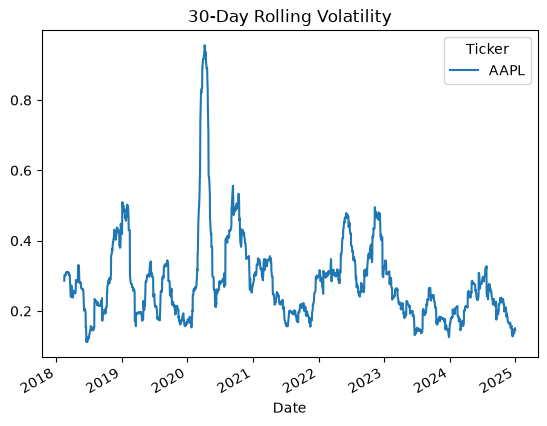

In [9]:
rolling_vol = rolling_volatility(
    returns,
    window=30
)

rolling_vol.plot(
    title="30-Day Rolling Volatility"
)

In [10]:
tickers = [
    "AAPL",
    "MSFT",
    "NVDA",
    "GOOG",
    "AMZN"
]
prices = load_market_data(tickers, "2018-01-01", "2025-01-01")
returns = prices["Close"].pct_change().dropna()
returns.head()

[*********************100%***********************]  5 of 5 completed


Ticker,AAPL,AMZN,GOOG,MSFT,NVDA
Date,,,,,
2018-01-03,-0.000174,0.012775,0.016413,0.004654,0.065814
2018-01-04,0.004645,0.004476,0.003621,0.008801,0.005272
2018-01-05,0.011385,0.016163,0.014571,0.012398,0.008474
2018-01-08,-0.003714,0.014425,0.004273,0.001021,0.030640
2018-01-09,-0.000115,0.004676,-0.000614,-0.000679,-0.000270


In [11]:
from analytics.portfolio import (
    correlation_matrix,
    portfolio_volatility
)
import numpy as np
annual_x_returns = returns.mean() * 252
weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
portfolio_return = np.dot(weights, annual_x_returns)
print(annual_x_returns)
annual_cov = returns.cov() * 252
portfolio_volatility = portfolio_volatility(weights, annual_cov)
print(portfolio_volatility)
print(annual_cov)

Ticker
AAPL    0.307545
AMZN    0.246211
GOOG    0.230315
MSFT    0.280436
NVDA    0.606041
dtype: float64
0.29793514038194474
Ticker      AAPL      AMZN      GOOG      MSFT      NVDA
Ticker                                                  
AAPL    0.093308  0.062988  0.060386  0.064371  0.093299
AMZN    0.062988  0.118437  0.069831  0.069065  0.103884
GOOG    0.060386  0.069831  0.094509  0.066084  0.093018
MSFT    0.064371  0.069065  0.066084  0.083443  0.098989
NVDA    0.093299  0.103884  0.093018  0.098989  0.265606


In [12]:
returns.std()
individual_volatility = returns.std() * np.sqrt(252)
print(individual_volatility.mean())


0.35225363286886335


In [13]:
results = []
from analytics.optimization import random_weights_constrained, simulate_portfolio


for i in range(10000):

    weights = random_weights_constrained(
        n_assets=5
    )

    portfolio_return, portfolio_volatility, sharpe = simulate_portfolio(
        weights,
        annual_x_returns,
        annual_cov
    )

    results.append(
        [
            portfolio_return,
            portfolio_volatility,
            sharpe,
            weights
        ]
    )


In [14]:

import pandas as pd


portfolio_results = pd.DataFrame(
    results,
    columns=[
        "return",
        "volatility",
        "sharpe",
        "weights"
    ]
)
portfolio_results.head()

,return,volatility,sharpe,weights
0,0.354123,0.308577,1.147600,"[0.29713118868535, 0.20116878822411402, 0.1942..."
1,0.355129,0.313776,1.131790,"[0.20901407268473304, 0.2814020998574456, 0.15..."
2,0.317641,0.288525,1.100913,"[0.28996356779557314, 0.2487749025271306, 0.12..."
3,0.295347,0.280393,1.053331,"[0.2310578213635298, 0.24914787686397652, 0.18..."
4,0.327736,0.293622,1.116183,"[0.2588109157305739, 0.1711673175853727, 0.245..."


In [15]:
import plotly.express as px


fig = px.scatter(
    portfolio_results,
    x="volatility",
    y="return",
    color="sharpe",
    title="Monte Carlo Portfolio Simulation",
    labels={
        "volatility": "Annual Volatility",
        "return": "Expected Annual Return"
    }
)

fig.show()

In [16]:
max_sharpe = portfolio_results.loc[
    portfolio_results["sharpe"].idxmax()
]
min_volatility = portfolio_results.loc[
    portfolio_results["volatility"].idxmin()
]
min_volatility

return                                                 0.269269
volatility                                              0.26879
sharpe                                                 1.001781
weights       [0.28155890323042315, 0.15555899160057252, 0.2...
Name: 9117, dtype: object

In [17]:
fig = px.scatter(
    portfolio_results,
    x="volatility",
    y="return",
    color="sharpe",
    title="Efficient Frontier Simulation"
)


fig.add_scatter(
    x=[max_sharpe["volatility"]],
    y=[max_sharpe["return"]],
    mode="markers",
    marker=dict(
        size=15
    ),
    name="Maximum Sharpe"
)


fig.add_scatter(
    x=[min_volatility["volatility"]],
    y=[min_volatility["return"]],
    mode="markers",
    marker=dict(
        size=15
    ),
    name="Minimum Volatility"
)


fig.show()

In [18]:
max_sharpe


return                                                 0.379537
volatility                                             0.316269
sharpe                                                 1.200048
weights       [0.29962732165582034, 0.09347288627949682, 0.0...
Name: 8570, dtype: object

In [19]:
from analytics.optimization import optimize_max_sharpe
max_sharpe_result = optimize_max_sharpe(
    annual_x_returns,
    annual_cov,
    risk_free_rate=0.0,
    max_weight=0.30
)
optimal_weights = max_sharpe_result.x

In [20]:
print(max_sharpe_result.success)
print(max_sharpe_result.message)

True
Optimization terminated successfully


In [21]:
optimal_weights = max_sharpe_result.x

import pandas as pd

optimal_allocation = pd.Series(
    optimal_weights,
    index=tickers,
    name="Weight"
)

print(optimal_allocation)

AAPL    0.300000
MSFT    0.022281
NVDA    0.077719
GOOG    0.300000
AMZN    0.300000
Name: Weight, dtype: float64


In [22]:
from analytics.portfolio import portfolio_volatility
optimal_weights = max_sharpe_result.x

optimal_return = optimal_weights @ annual_x_returns

optimal_volatility = portfolio_volatility(
    optimal_weights,
    annual_cov
)

optimal_sharpe = (
    optimal_return / optimal_volatility
)

print(f"Return:     {optimal_return:.2%}")
print(f"Volatility: {optimal_volatility:.2%}")
print(f"Sharpe:     {optimal_sharpe:.2f}")

Return:     38.16%
Volatility: 31.67%
Sharpe:     1.21


In [23]:
from analytics.optimization import optimize_min_volatility


min_vol_result = optimize_min_volatility(
    annual_cov,
    max_weight=0.30
)

min_vol_weights = min_vol_result.x

min_vol_return = min_vol_weights @ annual_x_returns

min_volatility = portfolio_volatility(
    min_vol_weights,
    annual_cov
)

min_vol_sharpe = (
    min_vol_return / min_volatility
)

print(min_vol_result.success)
print(min_vol_weights)

print(f"Return:     {min_vol_return:.2%}")
print(f"Volatility: {min_volatility:.2%}")
print(f"Sharpe:     {min_vol_sharpe:.2f}")

True
[0.3        0.11183305 0.28816695 0.3        0.        ]
Return:     27.03%
Volatility: 26.84%
Sharpe:     1.01


In [24]:
from analytics.optimization import optimize_for_target_return

target_result = optimize_for_target_return(
    annual_x_returns,
    annual_cov,
    target_return=0.30,
    max_weight=0.30
)

print(target_result.success)
print(target_result.message)
print(target_result.x)

True
Optimization terminated successfully
[0.3        0.09413453 0.2260644  0.3        0.07980108]


In [25]:
target_weights = target_result.x

target_return = (
    target_weights @ annual_x_returns
)

target_volatility = portfolio_volatility(
    target_weights,
    annual_cov
)

print(f"Return:     {target_return:.2%}")
print(f"Volatility: {target_volatility:.2%}")

Return:     30.00%
Volatility: 27.71%


In [26]:
min_return = min_vol_weights @ annual_x_returns
target_returns = np.linspace(
    min_return,
    0.40,
    30
)

In [27]:
frontier_returns = []
frontier_volatilities = []

for target in target_returns:

    result = optimize_for_target_return(
        annual_x_returns,
        annual_cov,
        target_return=target,
        max_weight=0.30
    )

    if result.success:
        weights = result.x

        volatility = portfolio_volatility(
            weights,
            annual_cov
        )

        frontier_returns.append(target)
        frontier_volatilities.append(volatility)

In [28]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=frontier_volatilities,
        y=frontier_returns,
        mode="lines+markers",
        name="Efficient Frontier"
    )
)

fig.update_layout(
    title="Efficient Frontier",
    xaxis_title="Annual Volatility",
    yaxis_title="Expected Annual Return"
)

fig.show()

In [29]:
import plotly.graph_objects as go

fig = go.Figure()

# Monte Carlo portfolios
fig.add_trace(
    go.Scatter(
        x=portfolio_results["volatility"],
        y=portfolio_results["return"],
        mode="markers",
        marker=dict(
            size=4,
            opacity=0.4,
            color=portfolio_results["sharpe"],
            showscale=True,
            colorbar=dict(title="Sharpe")
        ),
        name="Monte Carlo Portfolios"
    )
)

# Efficient frontier
fig.add_trace(
    go.Scatter(
        x=frontier_volatilities,
        y=frontier_returns,
        mode="lines",
        line=dict(width=4),
        name="Efficient Frontier"
    )
)

# Minimum volatility portfolio
fig.add_trace(
    go.Scatter(
        x=[min_volatility],
        y=[min_vol_return],
        mode="markers",
        marker=dict(size=14, symbol="diamond"),
        name="Minimum Volatility"
    )
)

# Maximum Sharpe portfolio
fig.add_trace(
    go.Scatter(
        x=[optimal_volatility],
        y=[optimal_return],
        mode="markers",
        marker=dict(size=14, symbol="star"),
        name="Maximum Sharpe"
    )
)

fig.update_layout(
    title="Portfolio Opportunity Set and Efficient Frontier",
    xaxis_title="Annual Volatility",
    yaxis_title="Expected Annual Return"
)

fig.show()

In [30]:
def random_weights_constrained(
    n_assets,
    max_weight=0.30
):
    while True:
        weights = np.random.random(n_assets)
        weights /= weights.sum()

        if np.all(weights <= max_weight):
            return weights

In [31]:
import plotly.graph_objects as go

fig = go.Figure()

# Monte Carlo portfolios
fig.add_trace(
    go.Scatter(
        x=portfolio_results["volatility"],
        y=portfolio_results["return"],
        mode="markers",
        marker=dict(
            size=4,
            opacity=0.4,
            color=portfolio_results["sharpe"],
            showscale=True,
            colorbar=dict(title="Sharpe")
        ),
        name="Monte Carlo Portfolios"
    )
)

# Efficient frontier
fig.add_trace(
    go.Scatter(
        x=frontier_volatilities,
        y=frontier_returns,
        mode="lines",
        line=dict(width=4),
        name="Efficient Frontier"
    )
)

# Minimum volatility portfolio
fig.add_trace(
    go.Scatter(
        x=[min_volatility],
        y=[min_vol_return],
        mode="markers",
        marker=dict(size=14, symbol="diamond"),
        name="Minimum Volatility"
    )
)

# Maximum Sharpe portfolio
fig.add_trace(
    go.Scatter(
        x=[optimal_volatility],
        y=[optimal_return],
        mode="markers",
        marker=dict(size=14, symbol="star"),
        name="Maximum Sharpe"
    )
)

fig.update_layout(
    title="Portfolio Opportunity Set and Efficient Frontier",
    xaxis_title="Annual Volatility",
    yaxis_title="Expected Annual Return"
)

fig.show()

In [32]:
expected_returns = returns.mean() * 252

In [33]:
perturbed_returns = expected_returns.copy()

perturbed_returns["NVDA"] -= 0.05

In [34]:
from analytics.optimization import optimize_max_sharpe
perturbed_result = optimize_max_sharpe(
    perturbed_returns,
    annual_cov,
    risk_free_rate=0.0,
    max_weight=0.30
)

perturbed_weights = perturbed_result.x

In [35]:
%whos

Variable                     Type              Data/Info
--------------------------------------------------------
annual_cov                   DataFrame         Shape: (5, 5)
annual_x_returns             Series            Shape: (5,)
annualized_volatility        function          <function annualized_volatility at 0x113367ba0>
calculate_simple_returns     function          <function calculate_simpl<...>e_returns at 0x11333c400>
correlation_matrix           function          <function correlation_matrix at 0x114bfd440>
data                         DataFrame         Shape: (1761, 5)
expected_returns             Series            Shape: (5,)
fig                          Figure            Figure({\n    'data': [{'<...>ted Annual Return'}}}\n})
frontier_returns             list              n=26
frontier_volatilities        list              n=26
go                           module            <module 'plotly.graph_obj<...>aph_objects/__init__.py'>
i                            int           

In [36]:
import pandas as pd
perturbed_result = optimize_max_sharpe(
    perturbed_returns,
    annual_cov,
    risk_free_rate=0.0,
    max_weight=0.30
)

perturbed_weights = perturbed_result.x

comparison = pd.DataFrame(
    {
        "Original": optimal_weights,
        "Perturbed": perturbed_weights
    },
    index=expected_returns.index
)

comparison["Change"] = (
    comparison["Perturbed"]
    - comparison["Original"]
)

comparison

,Original,Perturbed,Change
Ticker,,,
AAPL,0.300000,0.30000,5.551115e-17
AMZN,0.022281,0.02567,3.389230e-03
GOOG,0.077719,0.07433,-3.389230e-03
MSFT,0.300000,0.30000,-5.551115e-17
NVDA,0.300000,0.30000,0.000000e+00


In [37]:
turnover = (
    np.abs(
        perturbed_weights - optimal_weights
    ).sum()
    / 2
)

print(f"Portfolio turnover: {turnover:.2%}")

Portfolio turnover: 0.34%


In [38]:
unconstrained_original = optimize_max_sharpe(
    expected_returns,
    annual_cov,
    risk_free_rate=0.0,
    max_weight=1.0
)

unconstrained_perturbed = optimize_max_sharpe(
    perturbed_returns,
    annual_cov,
    risk_free_rate=0.0,
    max_weight=1.0
)

In [39]:
sensitivity_comparison = pd.DataFrame(
    {
        "Original": unconstrained_original.x,
        "Perturbed": unconstrained_perturbed.x
    },
    index=expected_returns.index
)

sensitivity_comparison["Change"] = (
    sensitivity_comparison["Perturbed"]
    - sensitivity_comparison["Original"]
)

sensitivity_comparison

,Original,Perturbed,Change
Ticker,,,
AAPL,4.254459e-01,4.529198e-01,2.747388e-02
AMZN,1.412645e-17,1.048838e-17,-3.638069e-18
GOOG,0.000000e+00,2.668049e-17,2.668049e-17
MSFT,7.651637e-02,1.650118e-01,8.849540e-02
NVDA,4.980377e-01,3.820684e-01,-1.159693e-01


In [40]:
turnover = (
    np.abs(
        unconstrained_perturbed.x
        - unconstrained_original.x
    ).sum()
    / 2
)

print(f"Portfolio turnover: {turnover:.2%}")

Portfolio turnover: 11.60%


In [41]:
from analytics.covariance import (
    sample_covariance,
    ledoit_wolf_covariance
)

ModuleNotFoundError: No module named 'analytics.covariance'

In [ ]:
sample_cov = sample_covariance(returns)

lw_cov, shrinkage = ledoit_wolf_covariance(
    returns
)

print(
    f"Ledoit-Wolf shrinkage: {shrinkage:.4f}"
)

Ledoit-Wolf shrinkage: 0.0068


In [ ]:
np.allclose(
    annual_cov.values,
    sample_cov.values
)

True

In [ ]:
difference = lw_cov - sample_cov

difference


Ticker,AAPL,AMZN,GOOG,MSFT,NVDA
Ticker,,,,,
AAPL,0.000202,-0.000461,-0.000442,-0.000471,-0.000683
AMZN,-0.000461,0.000018,-0.000511,-0.000506,-0.000760
GOOG,-0.000442,-0.000511,0.000193,-0.000484,-0.000681
MSFT,-0.000471,-0.000506,-0.000484,0.000274,-0.000725
NVDA,-0.000683,-0.000760,-0.000681,-0.000725,-0.001059


In [ ]:
relative_difference = (
    (lw_cov - sample_cov)
    / sample_cov
)

relative_difference

Ticker,AAPL,AMZN,GOOG,MSFT,NVDA
Ticker,,,,,
AAPL,0.002164,-0.007320,-0.007320,-0.007320,-0.007320
AMZN,-0.007320,0.000151,-0.007320,-0.007320,-0.007320
GOOG,-0.007320,-0.007320,0.002043,-0.007320,-0.007320
MSFT,-0.007320,-0.007320,-0.007320,0.003285,-0.007320
NVDA,-0.007320,-0.007320,-0.007320,-0.007320,-0.003988


In [ ]:
sample_result = optimize_max_sharpe(
    expected_returns,
    sample_cov,
    risk_free_rate=0.0,
    max_weight=0.30
)

In [ ]:
lw_result = optimize_max_sharpe(
    expected_returns,
    lw_cov,
    risk_free_rate=0.0,
    max_weight=0.30
)

In [ ]:
covariance_comparison = pd.DataFrame(
    {
        "Sample Covariance": sample_result.x,
        "Ledoit-Wolf": lw_result.x
    },
    index=expected_returns.index
)

covariance_comparison["Change"] = (
    covariance_comparison["Ledoit-Wolf"]
    - covariance_comparison["Sample Covariance"]
)

covariance_comparison

,Sample Covariance,Ledoit-Wolf,Change
Ticker,,,
AAPL,0.300000,0.300000,0.000000e+00
AMZN,0.022281,0.024104,1.823122e-03
GOOG,0.077719,0.075896,-1.823122e-03
MSFT,0.300000,0.300000,1.110223e-16
NVDA,0.300000,0.300000,0.000000e+00


In [ ]:
short_returns = returns.tail(60)

short_sample_cov = sample_covariance(
    short_returns
)

short_lw_cov, short_shrinkage = (
    ledoit_wolf_covariance(short_returns)
)

print(
    f"Full sample shrinkage: {shrinkage:.2%}"
)

print(
    f"60-day shrinkage: {short_shrinkage:.2%}"
)

Full sample shrinkage: 0.68%
60-day shrinkage: 14.94%


In [ ]:
mu_1y = returns.tail(252).mean() * 252
mu_3y = returns.tail(252 * 3).mean() * 252
mu_full = returns.mean() * 252

mu_comparison = pd.DataFrame({
    "1 Year": mu_1y,
    "3 Years": mu_3y,
    "Full Sample": mu_full
})

(mu_comparison * 100).round(2)

,1 Year,3 Years,Full Sample
Ticker,,,
AAPL,29.34,15.33,30.75
AMZN,40.70,15.68,24.62
GOOG,34.30,14.21,23.03
MSFT,14.16,11.68,28.04
NVDA,113.57,64.67,60.60


In [ ]:
import numpy as np

clean_returns = returns.dropna()

T = len(clean_returns)

mu = clean_returns.mean() * 252

mu_standard_error = (
    clean_returns.std()
    / np.sqrt(T)
    * 252
)

mu_uncertainty = pd.DataFrame({
    "Expected Return": mu,
    "Standard Error": mu_standard_error
})

(mu_uncertainty * 100).round(2)

,Expected Return,Standard Error
Ticker,,
AAPL,30.75,11.56
AMZN,24.62,13.02
GOOG,23.03,11.63
MSFT,28.04,10.93
NVDA,60.60,19.50


In [ ]:
from analytics.estimation import shrink_expected_returns

shrunk_mu, shrinkage_weights, target_mu = (
    shrink_expected_returns(returns)
)

mu_shrinkage_comparison = pd.DataFrame({
    "Historical": expected_returns,
    "Shrunk": shrunk_mu,
    "Weight on Historical": shrinkage_weights
})

print(f"Target return: {target_mu:.2%}")

mu_shrinkage_comparison

Target return: 33.41%


,Historical,Shrunk,Weight on Historical
Ticker,,,
AAPL,0.307545,0.326623,0.281823
AMZN,0.246211,0.313352,0.236149
GOOG,0.230315,0.305126,0.279243
MSFT,0.280436,0.317740,0.304981
NVDA,0.606041,0.367055,0.121154


In [ ]:
from backtesting.walk_forward import (
    walk_forward_backtest
)

wf_returns, wf_weights = walk_forward_backtest(
    returns,
    train_window=252,
    rebalance_frequency=21,
    max_weight=0.30
)

print(wf_returns.head())
print()
print(wf_weights.head())

Date
2019-01-04    0.049377
2019-01-07    0.009816
2019-01-08    0.011281
2019-01-09    0.006051
2019-01-10   -0.003395
dtype: float64

Ticker      AAPL      AMZN      GOOG  MSFT          NVDA
2019-01-04   0.1  0.300000  0.300000   0.3  1.942890e-16
2019-02-05   0.3  0.300000  0.100000   0.3  5.551115e-16
2019-03-07   0.1  0.300000  0.300000   0.3  1.496979e-14
2019-04-05   0.1  0.300000  0.300000   0.3  0.000000e+00
2019-05-07   0.3  0.214114  0.185886   0.3  0.000000e+00


In [ ]:
print("Backtest observations:", len(wf_returns))
print("Rebalances:", len(wf_weights))
print("Start:", wf_returns.index.min())
print("End:", wf_returns.index.max())

Backtest observations: 1508
Rebalances: 72
Start: 2019-01-04 00:00:00
End: 2024-12-31 00:00:00


In [ ]:
print("Prices:", prices.index.min(), prices.index.max())
print("Returns:", returns.index.min(), returns.index.max())
print("Clean returns:", returns.dropna().index.min(),
      returns.dropna().index.max())

Prices: 2018-01-02 00:00:00 2024-12-31 00:00:00
Returns: 2018-01-03 00:00:00 2024-12-31 00:00:00
Clean returns: 2018-01-03 00:00:00 2024-12-31 00:00:00


In [ ]:
equal_weights = np.ones(len(returns.columns)) / len(returns.columns)

benchmark_returns = (
    returns.loc[wf_returns.index]
    @ equal_weights
)

In [ ]:
from backtesting.metrics import performance_metrics

strategy_metrics = performance_metrics(wf_returns)
benchmark_metrics = performance_metrics(benchmark_returns)

comparison = pd.DataFrame({
    "Max Sharpe": strategy_metrics,
    "Equal Weight": benchmark_metrics
})

comparison

,Max Sharpe,Equal Weight
Total Return,6.720130,6.847069
CAGR,0.407116,0.410956
Volatility,0.313399,0.298150
Sharpe,1.247270,1.304747
Max Drawdown,-0.476898,-0.418249


<Axes: title={'center': 'Walk-Forward Portfolio Performance'}, xlabel='Date'>

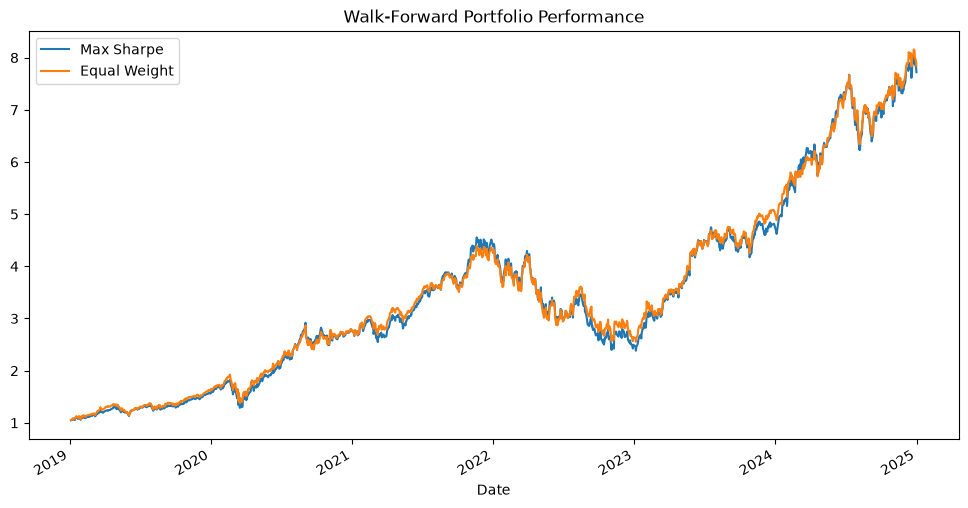

In [ ]:
strategy_wealth = (1 + wf_returns).cumprod()
benchmark_wealth = (1 + benchmark_returns).cumprod()

wealth = pd.DataFrame({
    "Max Sharpe": strategy_wealth,
    "Equal Weight": benchmark_wealth
})

wealth.plot(
    figsize=(12, 6),
    title="Walk-Forward Portfolio Performance"
)

In [ ]:
from backtesting.metrics import performance_metrics

strategy_metrics = performance_metrics(wf_returns)
benchmark_metrics = performance_metrics(benchmark_returns)

comparison = pd.DataFrame({
    "Max Sharpe": strategy_metrics,
    "Equal Weight": benchmark_metrics
})

comparison

,Max Sharpe,Equal Weight
Total Return,6.720130,6.847069
CAGR,0.407116,0.410956
Volatility,0.313399,0.298150
Sharpe,1.247270,1.304747
Max Drawdown,-0.476898,-0.418249


In [ ]:
from backtesting.walk_forward import (
    walk_forward_backtest,
    equal_weight_backtest
)
from backtesting.metrics import performance_metrics
wf_returns, wf_weights = walk_forward_backtest(
    returns,
    train_window=252,
    rebalance_frequency=21,
    max_weight=0.30
)


ew_returns, ew_weights = equal_weight_backtest(
    returns,
    train_window=252,
    rebalance_frequency=21
)

strategy_metrics = performance_metrics(wf_returns)
benchmark_metrics = performance_metrics(ew_returns)

comparison = pd.DataFrame({
    "Max Sharpe": strategy_metrics,
    "Equal Weight": benchmark_metrics
})

comparison

,Max Sharpe,Equal Weight
Total Return,6.801658,6.848304
CAGR,0.409588,0.410993
Volatility,0.313447,0.298056
Sharpe,1.252736,1.305174
Max Drawdown,-0.471992,-0.416108


In [ ]:
import os
import sys

print("Working directory:", os.getcwd())
print("\nPython search paths:")
for path in sys.path:
    print(path)

Working directory: /Users/himankarsharma/Documents/market-data-explorer/notebooks

Python search paths:
/Users/himankarsharma/.pyenv/versions/3.12.11/lib/python312.zip
/Users/himankarsharma/.pyenv/versions/3.12.11/lib/python3.12
/Users/himankarsharma/.pyenv/versions/3.12.11/lib/python3.12/lib-dynload

/Users/himankarsharma/.pyenv/versions/3.12.11/envs/quant-platform/lib/python3.12/site-packages
../src


In [ ]:
from backtesting.walk_forward import (
    walk_forward_backtest,
    equal_weight_backtest
)
sample_returns, sample_weights = walk_forward_backtest(
    returns,
    train_window=252,
    rebalance_frequency=21,
    max_weight=0.30,
    covariance_method="sample"
)

lw_returns, lw_weights = walk_forward_backtest(
    returns,
    train_window=252,
    rebalance_frequency=21,
    max_weight=0.30,
    covariance_method="ledoit_wolf"
)

In [ ]:
from backtesting.metrics import performance_metrics

comparison = pd.DataFrame({
    "Sample Cov": performance_metrics(sample_returns),
    "Ledoit-Wolf": performance_metrics(lw_returns),
    "Equal Weight": performance_metrics(ew_returns)
})

comparison

,Sample Cov,Ledoit-Wolf,Equal Weight
Total Return,6.801658,6.875383,6.848304
CAGR,0.409588,0.411805,0.410993
Volatility,0.313447,0.313593,0.298056
Sharpe,1.252736,1.257319,1.305174
Max Drawdown,-0.471992,-0.471465,-0.416108


In [ ]:
from backtesting.walk_forward import walk_forward_backtest
shrunk_returns, shrunk_weights = walk_forward_backtest(
    returns,
    train_window=252,
    rebalance_frequency=21,
    max_weight=0.30,
    covariance_method="ledoit_wolf",
    expected_return_method="shrunk"
)

ValueError: too many values to unpack (expected 2)

In [ ]:
from backtesting.metrics import performance_metrics
comparison = pd.DataFrame({
    "Historical μ + Sample Σ":
        performance_metrics(sample_returns),

    "Historical μ + LW Σ":
        performance_metrics(lw_returns),

    "Shrunk μ + LW Σ":
        performance_metrics(shrunk_returns),

    "Equal Weight":
        performance_metrics(ew_returns)
})

comparison

,Historical μ + Sample Σ,Historical μ + LW Σ,Shrunk μ + LW Σ,Equal Weight
Total Return,6.801658,6.875383,5.500719,6.848304
CAGR,0.409588,0.411805,0.367266,0.410993
Volatility,0.313447,0.313593,0.280710,0.298056
Sharpe,1.252736,1.257319,1.255339,1.305174
Max Drawdown,-0.471992,-0.471465,-0.321051,-0.416108


In [ ]:
def average_turnover(weights_history):
    weight_changes = weights_history.diff().dropna()

    turnover = (
        weight_changes.abs().sum(axis=1) / 2
    )

    return turnover.mean(), turnover

In [ ]:
sample_turnover, _ = average_turnover(sample_weights)
lw_turnover, _ = average_turnover(lw_weights)
shrunk_turnover, _ = average_turnover(shrunk_weights)
ew_turnover, _ = average_turnover(ew_weights)

print(f"Historical μ + Sample Σ: {sample_turnover:.2%}")
print(f"Historical μ + LW Σ:     {lw_turnover:.2%}")
print(f"Shrunk μ + LW Σ:         {shrunk_turnover:.2%}")
print(f"Equal Weight:             {ew_turnover:.2%}")

NameError: name 'sample_weights' is not defined

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
from backtesting.walk_forward import (
    walk_forward_backtest,
    equal_weight_backtest
)

In [ ]:
from backtesting.walk_forward import walk_forward_backtest
test_returns, test_weights, test_turnover = (
    walk_forward_backtest(
        returns,
        train_window=252,
        rebalance_frequency=21,
        max_weight=0.30,
        covariance_method="sample",
        expected_return_method="historical"
    )
)

In [ ]:
ew_returns, ew_weights, ew_turnover = (
    equal_weight_backtest(
        returns,
        train_window=252,
        rebalance_frequency=21
    )
)

In [ ]:
print("Optimizer observations:", len(test_returns))
print("Equal weight observations:", len(ew_returns))

print(
    "Same dates:",
    test_returns.index.equals(ew_returns.index)
)

Optimizer observations: 1508
Equal weight observations: 1508
Same dates: True


In [ ]:
print(
    "Optimizer weight sums:",
    test_weights.sum(axis=1).head()
)

print(
    "Equal-weight sums:",
    ew_weights.sum(axis=1).head()
)

Optimizer weight sums: 2019-01-04    1.0
2019-02-05    1.0
2019-03-07    1.0
2019-04-05    1.0
2019-05-07    1.0
dtype: float64
Equal-weight sums: 2019-01-04    1.0
2019-02-05    1.0
2019-03-07    1.0
2019-04-05    1.0
2019-05-07    1.0
dtype: float64


In [ ]:
assert np.allclose(
    test_weights.sum(axis=1),
    1.0
)

assert np.allclose(
    ew_weights.sum(axis=1),
    1.0
)

In [ ]:
print(ew_weights.head())

Ticker      AAPL  AMZN  GOOG  MSFT  NVDA
2019-01-04   0.2   0.2   0.2   0.2   0.2
2019-02-05   0.2   0.2   0.2   0.2   0.2
2019-03-07   0.2   0.2   0.2   0.2   0.2
2019-04-05   0.2   0.2   0.2   0.2   0.2
2019-05-07   0.2   0.2   0.2   0.2   0.2


In [ ]:
assert np.allclose(
    ew_weights.values,
    0.20
)

In [ ]:
print("Largest weight:", test_weights.max().max())
print("Smallest weight:", test_weights.min().min())

Largest weight: 0.3
Smallest weight: 0.0


In [ ]:
assert test_weights.max().max() <= 0.300001
assert test_weights.min().min() >= -0.000001

In [ ]:
print("Optimizer rebalances:", len(test_weights))
print("Optimizer turnover observations:", len(test_turnover))

print("Equal-weight rebalances:", len(ew_weights))
print("Equal-weight turnover observations:", len(ew_turnover))

Optimizer rebalances: 72
Optimizer turnover observations: 71
Equal-weight rebalances: 72
Equal-weight turnover observations: 71


In [ ]:
print(
    f"Optimizer average turnover: "
    f"{np.mean(test_turnover):.2%}"
)

print(
    f"Equal-weight average turnover: "
    f"{np.mean(ew_turnover):.2%}"
)

Optimizer average turnover: 11.69%
Equal-weight average turnover: 2.20%


In [ ]:
print("First 5 optimizer turnovers:")
print(test_turnover[:5])

print("\nFirst 5 equal-weight turnovers:")
print(ew_turnover[:5])

First 5 optimizer turnovers:
[np.float64(0.20208637328618537), np.float64(0.20476014284162417), np.float64(0.00870567310777134), np.float64(0.19795671802638437), np.float64(0.1022032583724029)]

First 5 equal-weight turnovers:
[np.float64(0.018781019316809408), np.float64(0.00612566186909097), np.float64(0.023849103818347428), np.float64(0.024100236107526804), np.float64(0.024766532959399706)]


In [ ]:
sample_returns, sample_weights, sample_turnover = (
    walk_forward_backtest(
        returns,
        train_window=252,
        rebalance_frequency=21,
        max_weight=0.30,
        covariance_method="sample",
        expected_return_method="historical"
    )
)

lw_returns, lw_weights, lw_turnover = (
    walk_forward_backtest(
        returns,
        train_window=252,
        rebalance_frequency=21,
        max_weight=0.30,
        covariance_method="ledoit_wolf",
        expected_return_method="historical"
    )
)

shrunk_returns, shrunk_weights, shrunk_turnover = (
    walk_forward_backtest(
        returns,
        train_window=252,
        rebalance_frequency=21,
        max_weight=0.30,
        covariance_method="ledoit_wolf",
        expected_return_method="shrunk"
    )
)

ew_returns, ew_weights, ew_turnover = (
    equal_weight_backtest(
        returns,
        train_window=252,
        rebalance_frequency=21
    )
)

In [ ]:
turnover_comparison = pd.Series({
    "Historical μ + Sample Σ": np.mean(sample_turnover),
    "Historical μ + LW Σ": np.mean(lw_turnover),
    "Shrunk μ + LW Σ": np.mean(shrunk_turnover),
    "Equal Weight": np.mean(ew_turnover)
})

print(
    turnover_comparison
    .map(lambda x: f"{x:.2%}")
)

Historical μ + Sample Σ    11.69%
Historical μ + LW Σ        11.59%
Shrunk μ + LW Σ            11.50%
Equal Weight                2.20%
dtype: str


In [ ]:
from backtesting.walk_forward import walk_forward_backtest, equal_weight_backtest
sample_returns_10bps, _, sample_turnover_10bps = (
    walk_forward_backtest(
        returns,
        train_window=252,
        rebalance_frequency=21,
        max_weight=0.30,
        covariance_method="sample",
        expected_return_method="historical",
        transaction_cost_bps=10
    )
)

ew_returns_10bps, _, ew_turnover_10bps = (
    equal_weight_backtest(
        returns,
        train_window=252,
        rebalance_frequency=21,
        transaction_cost_bps=10
    )
)

In [ ]:
from backtesting.metrics import performance_metrics
cost_comparison = pd.DataFrame({
    "Optimizer - 0 bps":
        performance_metrics(sample_returns),

    "Optimizer - 10 bps":
        performance_metrics(sample_returns_10bps),

    "Equal Weight - 0 bps":
        performance_metrics(ew_returns),

    "Equal Weight - 10 bps":
        performance_metrics(ew_returns_10bps)
})

cost_comparison

,Optimizer - 0 bps,Optimizer - 10 bps,Equal Weight - 0 bps,Equal Weight - 10 bps
Total Return,6.801661,6.737054,6.848305,6.836013
CAGR,0.409588,0.407631,0.410993,0.410624
Volatility,0.313447,0.313461,0.298056,0.298059
Sharpe,1.252737,1.248257,1.305174,1.304286
Max Drawdown,-0.471992,-0.473138,-0.416108,-0.416329


In [ ]:
assert np.allclose(
    sample_turnover,
    sample_turnover_10bps
)

In [ ]:
assert np.allclose(
    ew_turnover,
    ew_turnover_10bps
)

In [ ]:
cost_levels = [0, 5, 10, 25, 50]

optimizer_cost_results = {}
equal_weight_cost_results = {}

for cost in cost_levels:

    opt_returns, _, _ = walk_forward_backtest(
        returns,
        train_window=252,
        rebalance_frequency=21,
        max_weight=0.30,
        covariance_method="sample",
        expected_return_method="historical",
        transaction_cost_bps=cost
    )

    ew_cost_returns, _, _ = equal_weight_backtest(
        returns,
        train_window=252,
        rebalance_frequency=21,
        transaction_cost_bps=cost
    )

    optimizer_cost_results[cost] = performance_metrics(
        opt_returns
    )

    equal_weight_cost_results[cost] = performance_metrics(
        ew_cost_returns
    )

In [ ]:
cost_sensitivity = pd.DataFrame({
    "Cost (bps)": cost_levels,

    "Optimizer CAGR": [
        optimizer_cost_results[c]["CAGR"]
        for c in cost_levels
    ],

    "Equal Weight CAGR": [
        equal_weight_cost_results[c]["CAGR"]
        for c in cost_levels
    ],

    "Optimizer Sharpe": [
        optimizer_cost_results[c]["Sharpe"]
        for c in cost_levels
    ],

    "Equal Weight Sharpe": [
        equal_weight_cost_results[c]["Sharpe"]
        for c in cost_levels
    ]
})

cost_sensitivity

,Cost (bps),Optimizer CAGR,Equal Weight CAGR,Optimizer Sharpe,Equal Weight Sharpe
0,0,0.409588,0.410993,1.252737,1.305174
1,5,0.408609,0.410808,1.250497,1.304730
2,10,0.407631,0.410624,1.248257,1.304286
3,25,0.404699,0.410069,1.241533,1.302952
4,50,0.399825,0.409146,1.230312,1.300730


Text(0.5, 1.0, 'Transaction Cost Sensitivity')

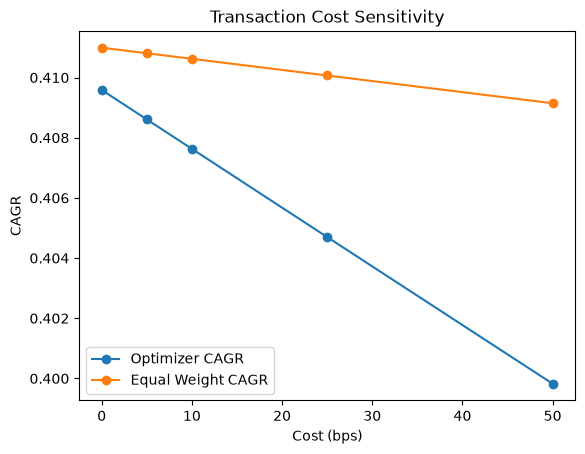

In [ ]:
ax = cost_sensitivity.plot(
    x="Cost (bps)",
    y=["Optimizer CAGR", "Equal Weight CAGR"],
    marker="o"
)

ax.set_ylabel("CAGR")
ax.set_title("Transaction Cost Sensitivity")

In [ ]:
training_windows = [126, 252, 504, 756]

window_results = {}

for window in training_windows:

    strategy_returns, _, turnover = walk_forward_backtest(
        returns,
        train_window=window,
        rebalance_frequency=21,
        max_weight=0.30,
        covariance_method="ledoit_wolf",
        expected_return_method="historical",
        transaction_cost_bps=10
    )

    metrics = performance_metrics(strategy_returns)

    window_results[window] = {
        **metrics,
        "Average Turnover": np.mean(turnover)
    }

window_comparison = pd.DataFrame(window_results).T

window_comparison[
    ["CAGR", "Volatility", "Sharpe",
     "Max Drawdown", "Average Turnover"]
]

,CAGR,Volatility,Sharpe,Max Drawdown,Average Turnover
126,0.348691,0.313554,1.111419,-0.430426,0.120993
252,0.409862,0.313605,1.252884,-0.472599,0.115875
504,0.359171,0.321554,1.115574,-0.428664,0.081301
756,0.312065,0.293948,1.070978,-0.411295,0.084389


In [ ]:
clean_returns = returns.dropna()

evaluation_start = clean_returns.index[756]

print(evaluation_start)

2021-01-05 00:00:00


In [42]:
from backtesting.walk_forward import walk_forward_backtest
from backtesting.metrics import performance_metrics
training_windows = [126, 252, 504, 756]

window_results = {}

for window in training_windows:

    strategy_returns, _, turnover = walk_forward_backtest(
        returns,
        train_window=window,
        rebalance_frequency=21,
        max_weight=0.30,
        covariance_method="ledoit_wolf",
        expected_return_method="historical",
        transaction_cost_bps=10,
        evaluation_start=evaluation_start
    )

    metrics = performance_metrics(strategy_returns)

    window_results[window] = {
        **metrics,
        "Average Turnover": np.mean(turnover),
        "Observations": len(strategy_returns),
        "Start": strategy_returns.index[0],
        "End": strategy_returns.index[-1]
    }

window_comparison = pd.DataFrame(window_results).T

window_comparison

NameError: name 'evaluation_start' is not defined